#### Project Overview

In 2026, Financial institutions face a surge of synthetic identities, real-time payment fraud, and adversarial AI attacks. Financial firms are under pressure to measure exact financial exposure from these real-time payment fraud, and generative AI drift. instead of giving leadership a single guess, confidence intervals provide a reliable range of risk. 

This project focuses on measuring the average of *likely AI/automated/scripted fraud* against *human-behavioral* fraud by using behavioral signals that humans rarely produce by scale, especially extreme velocity, and calculating a 95% confidence intervals for both to expose the financial exposure accross time.

In this project we describe high velocity applications (velocity_6h > 0.75 quantile) as a proxy for automated behaviour, not proof of AI involvement. And applications lower than the that velocity as human.

Dataset from NeurIPS Bank account fraud (BAF). This dataset is chosen over traditional anaonymized transaction logs because it captures modern digital attack vectors, such as velocity spikes, device anomalies, and credit-limit targetting - These reflects 2026 synthetic identity and automated bot fraud.

In [1]:
# Importing libraries 

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the dataset to pandas

df = pd.read_csv('../data/raw/Base.csv')

#### Exploratory Data Analysis (EDA)



In [3]:
df.head(5)

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


Our major variables for this analysis are:

- Fraud Bool: To filter only fraudulent values
- Velocity_6h: Our chosen variable to build a threshold for high velocity (Ai-proxy) applications
- Proposed credit-limit: To measue the financial exposure

In [4]:
# Data has 1M values
# No nulls

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  str    
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000000 non-nul

In [5]:
df.describe()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,...,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.0,1000000.000000
mean,0.011029,0.562696,0.493694,16.718568,86.587867,33.689080,1.025705e+00,8.661499,1572.692049,5665.296605,...,0.889676,10.839303,0.222988,515.851010,0.025242,7.544940,0.576947,1.018312,0.0,3.288674
std,0.104438,0.290343,0.289125,44.046230,88.406599,12.025799,5.381835e+00,20.236155,1005.374565,3009.380665,...,0.313293,12.116875,0.416251,487.559902,0.156859,8.033106,0.494044,0.180761,0.0,2.209994
min,0.000000,0.100000,0.000001,-1.000000,-1.000000,10.000000,4.036860e-09,-15.530555,1.000000,-170.603072,...,0.000000,-1.000000,0.000000,190.000000,0.000000,-1.000000,0.000000,-1.000000,0.0,0.000000
25%,0.000000,0.300000,0.225216,-1.000000,19.000000,20.000000,7.193246e-03,-1.181488,894.000000,3436.365848,...,1.000000,-1.000000,0.000000,200.000000,0.000000,3.103053,0.000000,1.000000,0.0,1.000000
50%,0.000000,0.600000,0.492153,-1.000000,52.000000,30.000000,1.517574e-02,-0.830507,1263.000000,5319.769349,...,1.000000,5.000000,0.000000,200.000000,0.000000,5.114321,1.000000,1.000000,0.0,3.000000
75%,0.000000,0.800000,0.755567,12.000000,130.000000,40.000000,2.633069e-02,4.984176,1944.000000,7680.717827,...,1.000000,25.000000,0.000000,500.000000,0.000000,8.866131,1.000000,1.000000,0.0,5.000000
max,1.000000,0.900000,0.999999,383.000000,428.000000,90.000000,7.845690e+01,112.956928,6700.000000,16715.565404,...,1.000000,32.000000,1.000000,2100.000000,1.000000,85.899143,1.000000,2.000000,0.0,7.000000


In [6]:
# is velocity_6h normally distributed

df['velocity_6h'].describe()

count    1000000.000000
mean        5665.296605
std         3009.380665
min         -170.603072
25%         3436.365848
50%         5319.769349
75%         7680.717827
max        16715.565404
Name: velocity_6h, dtype: float64

Text(0.5, 1.0, 'Distribution of velocity_6h')

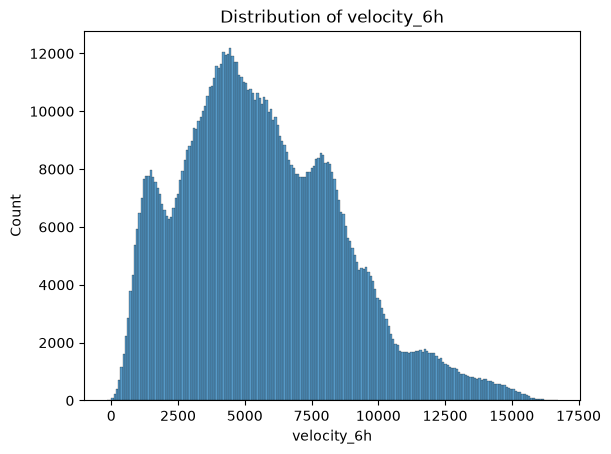

In [7]:
# plotting histogram for velocity_6h to check for skewness

sns.histplot(data = df, x = 'velocity_6h');

plt.title('Distribution of velocity_6h')

# velocity_6h is normally distributed. Has a bell shaped distribution

#### Extracting Needed Variables for our project analysis

In [8]:
# Extracting fraudulent applications

fraud_df  = df[df['fraud_bool'] == 1]

fraud_df.shape

(11029, 32)

In [9]:
# Bulding velocity threshold for ai proxy and human fraud

velocity_threshold = fraud_df['velocity_6h'].quantile(0.75)


In [10]:
# Bulding high velocity fraudulent applications

high_velocity_fraud = fraud_df[fraud_df['velocity_6h'] > velocity_threshold]

high_velocity_fraud_count = high_velocity_fraud['proposed_credit_limit'].count()
high_velocity_fraud_mean = high_velocity_fraud['proposed_credit_limit'].mean()

print(high_velocity_fraud_count)
print(high_velocity_fraud_mean)



2757
773.3151976786362


In [11]:
# Building human-like fraudulent applications

human_fraud = fraud_df[fraud_df['velocity_6h'] < velocity_threshold]
human_fraud_count = human_fraud['proposed_credit_limit'].count()
human_fraud_mean = human_fraud['proposed_credit_limit'].mean()

print(human_fraud_count)
print(human_fraud_mean)

8271
854.1300930963607


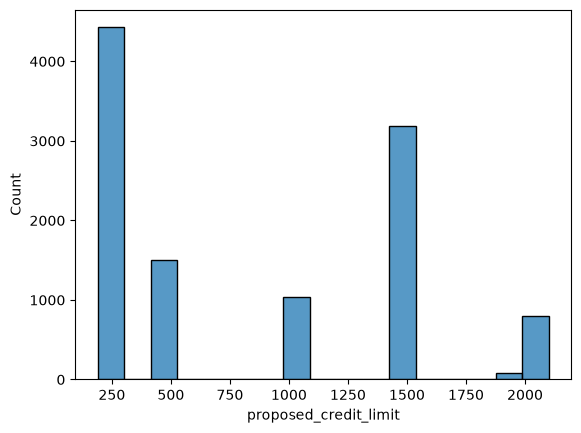

In [12]:
sns.histplot(data= fraud_df, x= 'proposed_credit_limit');

In [13]:

# checking the skewness of proposed credit limit values to decide whether to us bootstrap or normal distribution 95% CI

print(high_velocity_fraud['proposed_credit_limit'].skew())
print(human_fraud['proposed_credit_limit'].skew())

# Skewness is mild for both (0.47 and 0.35), meaning a standard normal interval would be valid.
#However, basedon the histogram, proposed_credit_limit is grouped into discrete tiers, so we use a 10,000-sample bootstrap as a robust method.
# rule of thumb on whether bootstrap CI or normal CI, below 0.5 = normal distribution, 0.5 -1.0 = borderline, safer bootstrap, above 1.0, recommend bootstrap.

0.4715224674861779
0.35493390152025917


In [14]:
# creating a bootstrapping distribution (resampling 10,000 times) to calculate mean distribution of financial exposure to high velocity fraudulent applications


np.random.seed(700)

high_velocity_sample_mean = []

for i in range(10000):
    high_velocity_sample = np.random.choice(high_velocity_fraud['proposed_credit_limit'], len(high_velocity_fraud['proposed_credit_limit']), replace = True )


    high_velocity_sample_mean.append(high_velocity_sample.mean())


In [15]:
# Calculating the upper and lower percentile for our bootstrap ci
# PCL means proposed credit limit

HVlower_ci = np.percentile(high_velocity_sample_mean, 2.5)
HVupper_ci = np.percentile(high_velocity_sample_mean, 97.5)


print(f'high velocity fraud count: {high_velocity_fraud_count:.2f}')
print(f'high velocity fraud mean(PCL): ${high_velocity_fraud_mean:.2f}')
print(f'95% Confidence Interval for high velocity fraud: (${HVlower_ci:.2f}, ${HVupper_ci:.2f}) ')

high velocity fraud count: 2757.00
high velocity fraud mean(PCL): $773.32
95% Confidence Interval for high velocity fraud: ($750.02, $796.98) 


In [16]:
# creating a bootstrapping distribution (resampling 10,000 times) to calculate mean distribution of financial exposure to human fraud


human_fraud_sample_mean = []

for i in range(10000):
    human_fraud_sample = np.random.choice(human_fraud['proposed_credit_limit'], len(human_fraud['proposed_credit_limit']), replace = True )


    human_fraud_sample_mean.append(human_fraud_sample.mean())


In [17]:
# Calculating the upper and lower percentile for our bootstrap ci
# PCL means proposed credit limit

HFlower_ci = np.percentile(human_fraud_sample_mean, 2.5)
HFupper_ci = np.percentile(human_fraud_sample_mean, 97.5)


print(f'human fraud count (PCL): {human_fraud_count:.2f}')
print(f'human fraud mean(PCL): ${human_fraud_mean:.2f}')
print(f'95% Confidence Interval for human fraud: (${HFlower_ci:.2f}, ${HFupper_ci:.2f}) ')

human fraud count (PCL): 8271.00
human fraud mean(PCL): $854.13
95% Confidence Interval for human fraud: ($840.32, $868.32) 


#### Findings:

- **High-Velocity (Automated/Bot) Fraud**: Average credit limit requested was **$773.32**, and we are 95% confident the true average sits between **$750.02 and $796.98.**

- **Standard (Human) Fraud:** Average credit limit requested is **$854.13**, and we are 95% confident the true average sits between **$840.32 and $868.32**.

What this means:

Two different fraud strategies:
- **Automated bots** apply fast and in huge numbers, asking for slightly smaller credit-limit (~$773) so they can slip past security checks without triggering alarms

- **Human fraudsters** move slower, spending more time crafting more applications so they can ask for larger credit limits (~$854) on each account.